In [ ]:
pip install minisom ucimlrepo scikit-learn pandas matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for minisom: filename=minisom-2.3.6-py3-none-any.whl size=13171 sha256=fae72f85c1868df14f0dc41be1d1cad1b4bb3c49a93acdd7148eb6c533cde65a
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built minisom
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [ucimlrepo]


In [4]:
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.preprocessing import StandardScaler
from ucimlrepo import fetch_ucirepo
from minisom import MiniSom

wine = fetch_ucirepo(id=109)
X = wine.data.features
y = wine.data.targets.iloc[:, 0].to_numpy()

Z = StandardScaler().fit_transform(X.values)

som = MiniSom(8, 8, Z.shape[1], sigma=1.5, learning_rate=0.5,
              neighborhood_function="gaussian", topology="rectangular", random_seed=42)
som.pca_weights_init(Z)
som.train(Z, 5000, random_order=True)

qe = som.quantization_error(Z)
te = som.topographic_error(Z)

winners = np.array([som.winner(z) for z in Z])
cell_labels = {}
for c, lab in zip(map(tuple, winners), y):
    cell_labels.setdefault(c, []).append(lab)
purity = sum(Counter(l).most_common(1)[0][1] for l in cell_labels.values()) / len(y)

pd.DataFrame({"kelas": y, "neuron_x": winners[:, 0], "neuron_y": winners[:, 1]}) \
    .to_csv("hasil_som_wine.csv", index=False)
pd.DataFrame({"metrik": ["quantization_error", "topographic_error", "purity"],
              "nilai": [qe, te, purity]}).to_csv("metrik_som_wine.csv", index=False)

np.save("umatrix_som_wine.npy", som.distance_map())
np.save("bobot_som_wine.npy", som.get_weights())

print("Quantization error :", qe)
print("Topographic error  :", te)
print("Purity             :", purity)

Quantization error : 1.4567902730883835
Topographic error  : 0.08426966292134831
Purity             : 0.9606741573033708


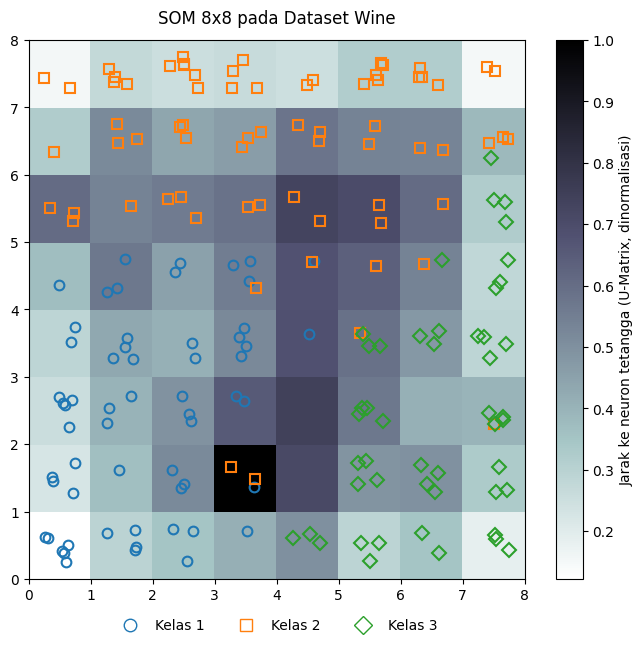

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

hasil = pd.read_csv("hasil_som_wine.csv")
umatrix = np.load("umatrix_som_wine.npy")

warna = {1: "tab:blue", 2: "tab:orange", 3: "tab:green"}
marker = {1: "o", 2: "s", 3: "D"}

plt.figure(figsize=(8, 7))
plt.pcolor(umatrix.T, cmap="bone_r")
plt.colorbar(label="Jarak ke neuron tetangga (U-Matrix, dinormalisasi)")

rng = np.random.default_rng(0)
for x, yy, lab in zip(hasil["neuron_x"], hasil["neuron_y"], hasil["kelas"]):
    plt.plot(x + 0.5 + rng.uniform(-0.25, 0.25), yy + 0.5 + rng.uniform(-0.25, 0.25),
             marker[lab], markerfacecolor="None", markeredgecolor=warna[lab],
             markersize=7, markeredgewidth=1.5)

plt.legend(handles=[Line2D([0], [0], marker=marker[k], color="w", markeredgecolor=warna[k],
                           markersize=9, label=f"Kelas {k}") for k in (1, 2, 3)],
           loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=3, frameon=False)
plt.title("SOM 8x8 pada Dataset Wine", pad=12)
plt.savefig("som_wine_umatrix.png", dpi=200, bbox_inches="tight")
plt.show()


In [7]:
import numpy as np

# Membaca kembali file .npy
bobot = np.load("bobot_som_wine.npy")
umatrix = np.load("umatrix_som_wine.npy")

# Menampilkan bentuk (shape) dan isinya
print("Shape bobot:", bobot.shape)
print("Isi bobot:\n", bobot)

Shape bobot: (8, 8, 13)
Isi bobot:
 [[[ 1.15364887e+00 -4.98345863e-01 -3.36895685e-01 -9.75247311e-01
    1.13603461e+00  1.24168584e+00  1.05174976e+00 -8.72217978e-01
    7.54957622e-01  4.16405791e-01 -3.26195567e-02  1.06358993e+00
    6.31563573e-01]
  [ 1.12192394e+00 -6.67636404e-01 -1.68728333e-01 -9.96011992e-01
    4.17599854e-01  1.39620804e+00  1.32226128e+00 -1.06041950e+00
    7.38125197e-01  7.48848891e-01  3.57195702e-02  9.45254250e-01
    1.24363667e+00]
  [ 1.43634534e+00 -5.67166411e-01  7.93482579e-02 -1.14280877e+00
    4.71430488e-01  1.36668030e+00  1.50625494e+00 -4.71035842e-01
    8.89112001e-01  1.04110310e+00  7.34215707e-01  4.94401806e-01
    2.17336493e+00]
  [ 1.80286664e+00 -5.87333749e-01 -3.68741622e-01 -1.59974620e+00
   -1.76016234e-01  8.80049192e-01  1.10294473e+00 -4.46338934e-01
    9.44867179e-01  3.04439878e-01  7.24640319e-01  4.01227660e-01
    1.36516515e+00]
  [ 3.30294630e-01 -6.49445057e-01 -1.03305523e+00 -1.65525891e+00
    1.5030645